# Fig. 6a: DefectNet against DFT formation energies

This notebook reproduces Fig. 6a of the DefectNet paper: the formation energies of 172 PBEsol charge states in 15
semiconductors from DFT and from DefectNet relaxations of a rattled start, each with its own chemical potentials. It first redraws the panel from the
DFT data and the paper's DefectNet energies, then repeats the DefectNet side for the Cu vacancy in CuGaSeTe in its
five charge states, the example in the inset, and compares with the paper.

Open this notebook from the `examples/paper/` folder of the repository. The DFT data it needs are in `data/` as
Apache Arrow tables (see `README.md` in this folder for the columns), and the model is the `DefectNet-v1.0.pt` weights file
of the v1.0 release.

## Install and download the model

The cell below installs TACE at commit `057e463` with the patch in `patches/`, the DefectNet package and `pyarrow`,
skipping every step that is already done. Install PyTorch for your machine first (pytorch.org). The weights
(`DefectNet-v1.0.pt`, 891 MB) are downloaded with the GitHub command-line tool unless a copy is already here or in
`examples/`.

In [1]:
%%bash
cd ../..                                         # repository root
if python -c "import tace" 2>/dev/null; then echo "TACE is already installed"
else
  git clone -q https://github.com/xvzemin/tace.git ../tace
  git -C ../tace checkout -q 057e463
  git -C ../tace apply "$PWD/patches/tace-057e463.patch"
  pip install -q -e ../tace
fi
python -c "import defectnet" 2>/dev/null && echo "DefectNet is already installed" || pip install -q -e .
python -c "import pyarrow" 2>/dev/null && echo "pyarrow is already installed" || pip install -q pyarrow
cd examples/paper
if [ -f DefectNet-v1.0.pt ]; then echo "DefectNet-v1.0.pt is already here"
elif [ -f ../DefectNet-v1.0.pt ]; then ln -s ../DefectNet-v1.0.pt . && echo "using ../DefectNet-v1.0.pt"
else gh release download v1.0 -R msehabibur/DefectNet -p DefectNet-v1.0.pt; fi

TACE is already installed


DefectNet is already installed


pyarrow is already installed


DefectNet-v1.0.pt is already here


## Load the model and the data

Every row of an Arrow table is one DFT calculation. `atoms(row)` builds the ASE structure the benchmark started from
(the DFT input geometry of a defect cell, the DFT final geometry of a pristine cell), and `seed(row)` is the random
seed of its rattle, the CRC32 checksum of the row's `path`, so a relaxation here starts from exactly the same
displaced atoms as in the paper. GPU arithmetic is not bit-for-bit reproducible across devices, so energies can
differ from the paper values by a few meV.

In [2]:
import logging
import warnings
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)                 # hides TACE's start-up notes

import zlib
import numpy as np
import matplotlib.pyplot as plt
import pyarrow.feather as feather
from ase import Atoms

import defectnet as dn


def table(name):
    return feather.read_table(f"data/{name}.arrow").to_pylist()


def atoms(row, positions="start_positions"):
    return Atoms(row["start_symbols"], positions=row[positions], cell=row["start_cell"], pbc=True)


def seed(row):
    return zlib.crc32(row["path"].encode())


calc = dn.load("DefectNet-v1.0.pt", functional="PBEsol")
cells = table("fig6a_cells")
pristine = {r["path"]: r for r in table("pristine_pbesol")}
print(len(cells), "defect cells and", len(pristine), "pristine cells, PBEsol")

172 defect cells and 15 pristine cells, PBEsol


## Formation energies from the DFT data

For a defect cell with charge $q$, with $n_i = +1$ for an atom added and $-1$ for an atom removed,

$$E^{f}(q, E_F = 0) = E_{def}(q) - E_{bulk} - \sum_i n_i \mu_i + q\,E_{VBM}.$$

The Fermi level is at the PBEsol valence-band maximum (VBM) of the pristine cell, and no finite-size correction is
applied. The chemical potentials $\mu_i$ are those of the limit stored with each row: the DFT values (`mu_values`) for
DFT and the DefectNet values at the same limit (`mu_defectnet`, from the DefectNet energies of the competing phases)
for DefectNet. The cell below recomputes both from the stored energies and checks them against the columns `Ef0_dft`
and `Ef0_defectnet_paper`.

In [3]:
def ef0(r, e_def, e_bulk, mu="mu_values"):
    change = dict(zip(r["change_elements"], r["change_counts"]))
    return dn.formation_energy(e_def, e_bulk, change, dict(zip(r["mu_elements"], r[mu])), r["q"], r["vbm"])


def ef0_dn(r, e_def, e_bulk):
    return ef0(r, e_def, e_bulk, "mu_defectnet")


check = [ef0(r, r["E_dft"], pristine[r["pristine"]]["E_dft"]) - r["Ef0_dft"] for r in cells]
check += [ef0_dn(r, r["E_defectnet_paper"], pristine[r["pristine"]]["E_defectnet_paper"]) - r["Ef0_defectnet_paper"] for r in cells]
print(f"largest difference from the stored values: {max(map(abs, check)):.1e} eV")

largest difference from the stored values: 5.0e-05 eV


## The panel

The DefectNet values use the same formula with the DefectNet energies of the relaxed defect and pristine cells
(columns `E_defectnet_paper`) and the DefectNet chemical potentials. The root-mean-square error (RMSE) over the
$N$ charge states is

$$\mathrm{RMSE} = \Big[\frac{1}{N}\sum_k \big(E^{f}_{k,DN} - E^{f}_{k,DFT}\big)^2\Big]^{1/2}.$$

172 charge states, RMSE 0.34 eV (paper: 172, 0.34 eV)


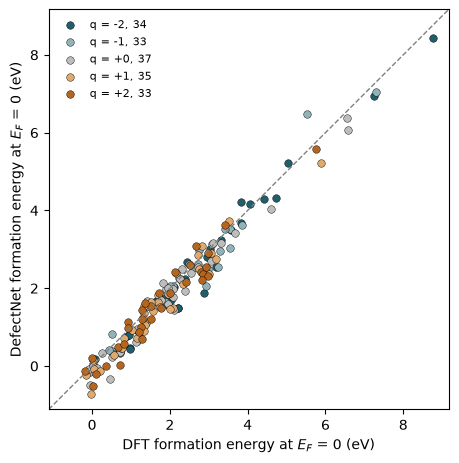

In [4]:
x = np.array([r["Ef0_dft"] for r in cells])
y = np.array([ef0_dn(r, r["E_defectnet_paper"], pristine[r["pristine"]]["E_defectnet_paper"]) for r in cells])
q = np.array([r["q"] for r in cells])
rmse = lambda v: float(np.sqrt(np.mean(np.square(v))))
print(f"{len(cells)} charge states, RMSE {rmse(y - x):.2f} eV (paper: 172, 0.34 eV)")

QCOL = {-2: "#1f5f6b", -1: "#8fb3b8", 0: "#bdbdbd", 1: "#e0a96d", 2: "#b5651d"}


def parity(ax):
    lo, hi = min(x.min(), y.min()) - 0.4, max(x.max(), y.max()) + 0.4
    ax.plot([lo, hi], [lo, hi], "--", color="grey", lw=1)
    for k in sorted(QCOL):
        m = q == k
        ax.scatter(x[m], y[m], s=30, color=QCOL[k], edgecolor="k", lw=0.3, label=f"q = {k:+d}, {m.sum()}")
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal")
    ax.set_xlabel("DFT formation energy at $E_F$ = 0 (eV)")
    ax.set_ylabel("DefectNet formation energy at $E_F$ = 0 (eV)")


fig, ax = plt.subplots(figsize=(5.2, 5.2))
parity(ax)
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()

## Worked example: V$_{Cu}$ in CuGaSeTe

Each cell is rattled with Gaussian displacements of 10% of its shortest interatomic distance and relaxed with FIRE
at a fixed cell until the largest force is below 0.02 eV/Å, at the total charge of the DFT calculation. `dn.relax`
does both steps; the trajectory files keep the energy after every step, which is the inset of Fig. 6a. The pristine
cell is relaxed the same way from its DFT geometry. This takes about five minutes on one GPU.

In [5]:
import os
from ase.io import read

os.makedirs("out", exist_ok=True)
vcu = sorted((r for r in cells if r["host"] == "Cu1Ga1Se1Te1_stannite" and r["defect"] == "Vac_Cu"), key=lambda r: -r["q"])
P = pristine[vcu[0]["pristine"]]
bulk = dn.relax(atoms(P), calc, q=0, seed=seed(P))
print(f"pristine CuGaSeTe, {len(bulk)} atoms: E = {bulk.info['energy']:.3f} eV (paper {P['E_defectnet_paper']:.3f} eV), "
      f"{bulk.info['steps']} steps")

traj = {}
print(" q   E_f DFT   E_f DefectNet (paper)   E_f DefectNet (this run)   steps")
for r in vcu:
    a = dn.relax(atoms(r), calc, q=r["q"], seed=seed(r), trajectory=f"out/vcu_{r['q']:+d}.traj")
    traj[r["q"]] = [s.get_potential_energy() for s in read(f"out/vcu_{r['q']:+d}.traj", ":")]
    e = ef0_dn(r, a.info["energy"], bulk.info["energy"])
    print(f"{r['q']:+d}   {r['Ef0_dft']:7.3f}   {r['Ef0_defectnet_paper']:7.3f}                 {e:7.3f}                  "
          f"{a.info['steps']:4d}  converged {a.info['converged']}")

pristine CuGaSeTe, 288 atoms: E = -1173.655 eV (paper -1173.655 eV), 87 steps
 q   E_f DFT   E_f DefectNet (paper)   E_f DefectNet (this run)   steps


+2     0.367     0.003                   0.002                    84  converged True


+1     0.209    -0.117                  -0.118                    84  converged True


+0     0.131    -0.041                  -0.041                    80  converged True


-1     0.086    -0.045                  -0.045                    87  converged True


-2     0.072    -0.153                  -0.153                    84  converged True


The inset: the DefectNet total energy at each FIRE step of the five relaxations, with a dot at the converged structure.

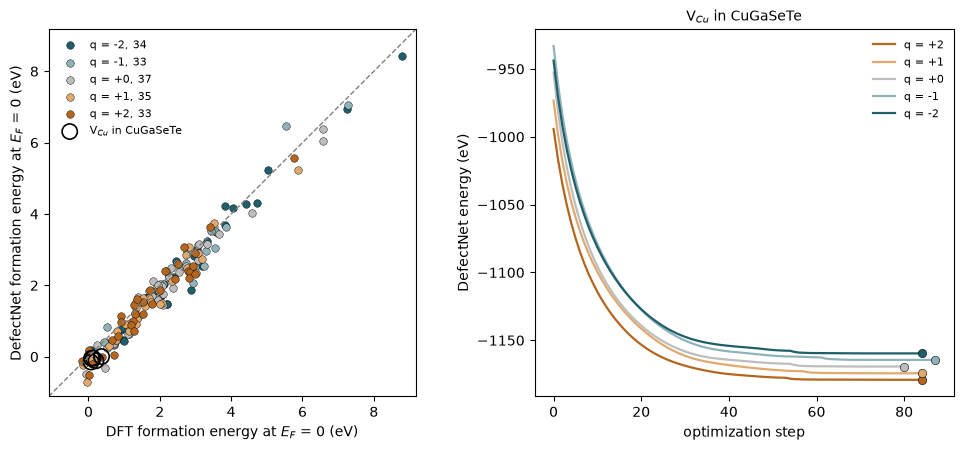

In [6]:
fig, (ax, ai) = plt.subplots(1, 2, figsize=(10, 4.6))
parity(ax)
ax.scatter([r["Ef0_dft"] for r in vcu], [r["Ef0_defectnet_paper"] for r in vcu], s=120, facecolor="none",
           edgecolor="k", lw=1.2, label=r"V$_{Cu}$ in CuGaSeTe")
ax.legend(frameon=False, fontsize=8, loc="upper left")
for k, t in traj.items():
    ai.plot(t, color=QCOL[k], lw=1.6, label=f"q = {k:+d}")
    ai.plot(len(t) - 1, t[-1], "o", color=QCOL[k], mec="k", mew=0.4)
ai.set_xlabel("optimization step")
ai.set_ylabel("DefectNet energy (eV)")
ai.set_title(r"V$_{Cu}$ in CuGaSeTe", fontsize=10)
ai.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## All 172 cells

Set `RUN_ALL = True` to relax every defect and pristine cell of the panel the same way (about three hours on
one GPU) and redraw the panel from your own DefectNet energies.

In [7]:
RUN_ALL = False
if RUN_ALL:
    e_bulk = {p: dn.relax(atoms(P), calc, q=0, seed=seed(P)).info["energy"] for p, P in pristine.items()}
    y_new = np.array([ef0_dn(r, dn.relax(atoms(r), calc, q=r["q"], seed=seed(r)).info["energy"], e_bulk[r["pristine"]]) for r in cells])
    print(f"{len(cells)} charge states: RMSE {rmse(y_new - x):.2f} eV (paper: 0.34 eV)")